In [40]:
#SETUP
import pandas as pd
import numpy as np
import sqlite3
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
os.chdir('/content/sample_data/')

In [41]:
#EXTRACTION
df = pd.read_csv('US_cities_2026.txt', sep="|",quotechar="'")
print("The raw table extracted into a dataframe:")
print(df.shape)
print(df.columns)
print(df.dtypes)
df.head()

The raw table extracted into a dataframe:
(250, 11)
Index(['Order', 'State_City', 'Population', 'Budget', 'Mayor', 'Gender',
       'Begin_Term', 'End_Term', 'Govern_Type', 'foo1', 'foo2'],
      dtype='object')
Order          object
State_City     object
Population     object
Budget         object
Mayor          object
Gender         object
Begin_Term      int64
End_Term        int64
Govern_Type    object
foo1           object
foo2           object
dtype: object


,Order,State_City,Population,Budget,Mayor,Gender,Begin_Term,End_Term,Govern_Type,foo1,foo2
0,"""1","New York, New York","8,584,629","$115,900,000,000","Zohran Mamdani (1991-10-18, D)",M,2026,2030,Strong mayor,No,"No"""
1,"""2","Los Angeles, California","3,869,089","$12,800,000,000","Karen Bass (1953-10-03, D)",F,2022,2026,Strong mayor,Yes,"Yes"""
2,"""3","Chicago, Illinois","2,731,585","$17,300,000,000","Brandon Johnson (1976-03-27, D)",M,2023,2027,Strong mayor,Yes,"No"""
3,"""4","Houston, Texas","2,397,315","$6,700,000,000","John Whitmire (1949-08-13, D)",M,2024,2028,Strong mayor,No,"No"""
4,"""5","Philadelphia, Pennsylvania","1,574,281","$6,400,000,000","Cherelle Parker (1972-09-09, D)",F,2024,2028,Strong mayor,Yes,"Yes"""


In [42]:
#TRANSFORM_CLEANING
# Note: the terms "City commission" and "Commission" were combined into
# one value "Commission" as I am treating them as identical government types.

df['State_City'] = df['State_City'].str.strip() #State_City kept as the unique row identifier for Power BI
df[['City', 'State']] = df['State_City'].str.split(',', n=1, expand=True).apply(lambda s: s.str.strip())
df['Population'] = df['Population'].str.replace(',', '').str.strip().astype(int)
df['Budget'] = df['Budget'].str.replace(',', '').str.replace('$', '').str.strip().astype(int)
df['Gender'] = df['Gender'].str.strip()
df['Govern_Type'] = df['Govern_Type'].str.replace('*', '', regex=False).str.strip().replace('City commission','Commission') #see note above
df['foo1']=df['foo1'].str.strip()
df['foo2']=df['foo2'].str.replace('"', '').str.strip()
df[['Mayor_Name', 'Birth_Year', 'Party']] = df['Mayor'].str.extract(r"^(.*?)\s*\((.*?),\s*(\w+)\)\s*$")
df['Birth_Year'] = pd.to_numeric(df['Birth_Year'].str[:4], errors='coerce').astype('Int64')
df = df.drop(columns=['Mayor','Order']) #Order dropped per Kelvin
df.head()


,State_City,Population,Budget,Gender,Begin_Term,End_Term,Govern_Type,foo1,foo2,City,State,Mayor_Name,Birth_Year,Party
0,"New York, New York",8584629,115900000000,M,2026,2030,Strong mayor,No,No,New York,New York,Zohran Mamdani,1991,D
1,"Los Angeles, California",3869089,12800000000,F,2022,2026,Strong mayor,Yes,Yes,Los Angeles,California,Karen Bass,1953,D
2,"Chicago, Illinois",2731585,17300000000,M,2023,2027,Strong mayor,Yes,No,Chicago,Illinois,Brandon Johnson,1976,D
3,"Houston, Texas",2397315,6700000000,M,2024,2028,Strong mayor,No,No,Houston,Texas,John Whitmire,1949,D
4,"Philadelphia, Pennsylvania",1574281,6400000000,F,2024,2028,Strong mayor,Yes,Yes,Philadelphia,Pennsylvania,Cherelle Parker,1972,D


In [43]:
#TRANSFORM_DERIVED_COLUMNS

# region data needed for analysis and missing from raw data file.
# dictionary made from US Census, and per instructions from class, District of Columbia treated
# as 51st State
state_region = {
    'Alabama': 'South',
    'Alaska': 'West',
    'Arizona': 'West',
    'Arkansas': 'South',
    'California': 'West',
    'Colorado': 'West',
    'Connecticut': 'Northeast',
    'Delaware': 'South',
    'District of Columbia': 'South',
    'Florida': 'South',
    'Georgia': 'South',
    'Hawaii': 'West',
    'Idaho': 'West',
    'Illinois': 'Midwest',
    'Indiana': 'Midwest',
    'Iowa': 'Midwest',
    'Kansas': 'Midwest',
    'Kentucky': 'South',
    'Louisiana': 'South',
    'Maine': 'Northeast',
    'Maryland': 'South',
    'Massachusetts': 'Northeast',
    'Michigan': 'Midwest',
    'Minnesota': 'Midwest',
    'Mississippi': 'South',
    'Missouri': 'Midwest',
    'Montana': 'West',
    'Nebraska': 'Midwest',
    'Nevada': 'West',
    'New Hampshire': 'Northeast',
    'New Jersey': 'Northeast',
    'New Mexico': 'West',
    'New York': 'Northeast',
    'North Carolina': 'South',
    'North Dakota': 'Midwest',
    'Ohio': 'Midwest',
    'Oklahoma': 'South',
    'Oregon': 'West',
    'Pennsylvania': 'Northeast',
    'Rhode Island': 'Northeast',
    'South Carolina': 'South',
    'South Dakota': 'Midwest',
    'Tennessee': 'South',
    'Texas': 'South',
    'Utah': 'West',
    'Vermont': 'Northeast',
    'Virginia': 'South',
    'Washington': 'West',
    'West Virginia': 'South',
    'Wisconsin': 'Midwest',
    'Wyoming': 'West'
}

df['Region']=df['State'].map(state_region)
df['Budget_per_Capita'] = (df['Budget'] / df['Population']).round(2) #corrects value mismatch that occurs when reading the CSV output file
df['Bloc'] = np.where(df['Party'] == 'R', 'Republican','Democratic caucus') #I and NP are considered part of Democratic caucus
df.head()

,State_City,Population,Budget,Gender,Begin_Term,End_Term,Govern_Type,foo1,foo2,City,State,Mayor_Name,Birth_Year,Party,Region,Budget_per_Capita,Bloc
0,"New York, New York",8584629,115900000000,M,2026,2030,Strong mayor,No,No,New York,New York,Zohran Mamdani,1991,D,Northeast,13500.87,Democratic caucus
1,"Los Angeles, California",3869089,12800000000,F,2022,2026,Strong mayor,Yes,Yes,Los Angeles,California,Karen Bass,1953,D,West,3308.27,Democratic caucus
2,"Chicago, Illinois",2731585,17300000000,M,2023,2027,Strong mayor,Yes,No,Chicago,Illinois,Brandon Johnson,1976,D,Midwest,6333.32,Democratic caucus
3,"Houston, Texas",2397315,6700000000,M,2024,2028,Strong mayor,No,No,Houston,Texas,John Whitmire,1949,D,South,2794.79,Democratic caucus
4,"Philadelphia, Pennsylvania",1574281,6400000000,F,2024,2028,Strong mayor,Yes,Yes,Philadelphia,Pennsylvania,Cherelle Parker,1972,D,Northeast,4065.35,Democratic caucus


In [44]:
#Part 5a - adding City_Size and Budget_Size

city_edges = [0, 1.5e5, 2.5e5, 5e5, 1e6, np.inf]
labels = ['Tiny','Small','Medium','Large','Major']

df['City_Size'] = pd.cut(df['Population'], bins=city_edges, labels=labels, right=False)
print(df['City_Size'].value_counts(sort=False).sort_index(ascending=False))

budget_edges = [0, 5e8, 1e9, 2e9, 5e9, np.inf]

df['Budget_Size'] = pd.cut(df['Budget'], bins=budget_edges, labels=labels, right=False)
df['Budget_Size'].value_counts(sort=False).sort_index(ascending=False)



City_Size
Major     12
Large     27
Medium    53
Small     91
Tiny      67
Name: count, dtype: int64


,count
Budget_Size,
Major,12
Large,26
Medium,48
Small,104
Tiny,60


In [45]:
#VALIDATE
assert len(df) == 250, "Error! 250 rows expected"
assert not df[['City','State']].duplicated().any(), "Error! Repeated city and state found."
assert (df[['Population','Budget']]).notna().all().all() and \
    pd.api.types.is_numeric_dtype(df['Population']) and \
    pd.api.types.is_numeric_dtype(df['Budget']), "Error! Expected non-empty and numeric values."

assert (df[['Party','Region']]).notna().all().all(), \
    "Error! Expected non-empty values."
assert df['Party'].isin(['D', 'R', 'I', 'NP']).all(), \
    "Error! Unexpected Party value."
no_birth_years = df['Birth_Year'].isna().sum()
print(f"{no_birth_years} mayors have no stated birth year. This is {no_birth_years/len(df):.1%} of the total.")

print("Sample line from dataframe:")
print(df[((df['City'] == 'Fort Lauderdale') & (df['State'] == 'Florida'))].T)
print("Corresponding line from raw file:")
with open('US_cities_2026.txt', 'r') as fh:
    line_141_raw = [raw_line for raw_line in fh if raw_line.startswith('"141')]
print(line_141_raw[0])
df.head()

198 mayors have no stated birth year. This is 79.2% of the total.
Sample line from dataframe:
                                        140
State_City         Fort Lauderdale, Florida
Population                           188677
Budget                            735510000
Gender                                    M
Begin_Term                             2024
End_Term                               2028
Govern_Type                 Council-manager
foo1                                     No
foo2                                     No
City                        Fort Lauderdale
State                               Florida
Mayor_Name                   Dean Trantalis
Birth_Year                             <NA>
Party                                     D
Region                                South
Budget_per_Capita                   3898.25
Bloc                      Democratic caucus
City_Size                             Small
Budget_Size                           Small
Corresponding line from ra

,State_City,Population,Budget,Gender,Begin_Term,End_Term,Govern_Type,foo1,foo2,City,State,Mayor_Name,Birth_Year,Party,Region,Budget_per_Capita,Bloc,City_Size,Budget_Size
0,"New York, New York",8584629,115900000000,M,2026,2030,Strong mayor,No,No,New York,New York,Zohran Mamdani,1991,D,Northeast,13500.87,Democratic caucus,Major,Major
1,"Los Angeles, California",3869089,12800000000,F,2022,2026,Strong mayor,Yes,Yes,Los Angeles,California,Karen Bass,1953,D,West,3308.27,Democratic caucus,Major,Major
2,"Chicago, Illinois",2731585,17300000000,M,2023,2027,Strong mayor,Yes,No,Chicago,Illinois,Brandon Johnson,1976,D,Midwest,6333.32,Democratic caucus,Major,Major
3,"Houston, Texas",2397315,6700000000,M,2024,2028,Strong mayor,No,No,Houston,Texas,John Whitmire,1949,D,South,2794.79,Democratic caucus,Major,Major
4,"Philadelphia, Pennsylvania",1574281,6400000000,F,2024,2028,Strong mayor,Yes,Yes,Philadelphia,Pennsylvania,Cherelle Parker,1972,D,Northeast,4065.35,Democratic caucus,Major,Major


In [46]:
#LOAD

check_list = ['State_City', 'Population', 'Budget', 'Gender', 'Begin_Term',
       'End_Term', 'Govern_Type', 'foo1', 'foo2', 'City', 'State',
       'Mayor_Name', 'Birth_Year', 'Party', 'Region', 'Budget_per_Capita',
       'Bloc', 'City_Size', 'Budget_Size']
df[check_list].to_csv('us_cities_clean.csv', index=False)

tier_type = pd.CategoricalDtype(categories=labels, ordered=True)
#CSV doesn’t store types, so Birth_Year has to be told to come back as Int64
#CSV doesn’t store ordered types, so City_Size and Budget_Size have to be told to come back as ordered category
dtype_dict ={'Birth_Year':'Int64','City_Size':tier_type,'Budget_Size':tier_type}
check = pd.read_csv('us_cities_clean.csv', dtype=dtype_dict)
print(f'Shape: {check.shape}')
print('=='*50)
print(f'Columns: {check.columns}')
print('=='*50)
print(f'Data Types: \n{df[check_list].dtypes}')
print('=='*50)
print(f'Data Types from CSV: \n')
print(check.dtypes)
print('=='*50)
print('Verify Data Types from CSV match Data Types from Dataframe:')
print(df[check_list].dtypes == check.dtypes)
print('=='*50)
print('Verify Shape and Elements from CSV match Shape and Elements from Dataframe:')
print(df[check_list].equals(check))

for i in df[check_list]:
    if not df[i].equals(check[i]):
        print(f'column {i} failed')

print('=='*50)
df[check_list].head()

Shape: (250, 19)
Columns: Index(['State_City', 'Population', 'Budget', 'Gender', 'Begin_Term',
       'End_Term', 'Govern_Type', 'foo1', 'foo2', 'City', 'State',
       'Mayor_Name', 'Birth_Year', 'Party', 'Region', 'Budget_per_Capita',
       'Bloc', 'City_Size', 'Budget_Size'],
      dtype='object')
Data Types: 
State_City             object
Population              int64
Budget                  int64
Gender                 object
Begin_Term              int64
End_Term                int64
Govern_Type            object
foo1                   object
foo2                   object
City                   object
State                  object
Mayor_Name             object
Birth_Year              Int64
Party                  object
Region                 object
Budget_per_Capita     float64
Bloc                   object
City_Size            category
Budget_Size          category
dtype: object
Data Types from CSV: 

State_City             object
Population              int64
Budget           

,State_City,Population,Budget,Gender,Begin_Term,End_Term,Govern_Type,foo1,foo2,City,State,Mayor_Name,Birth_Year,Party,Region,Budget_per_Capita,Bloc,City_Size,Budget_Size
0,"New York, New York",8584629,115900000000,M,2026,2030,Strong mayor,No,No,New York,New York,Zohran Mamdani,1991,D,Northeast,13500.87,Democratic caucus,Major,Major
1,"Los Angeles, California",3869089,12800000000,F,2022,2026,Strong mayor,Yes,Yes,Los Angeles,California,Karen Bass,1953,D,West,3308.27,Democratic caucus,Major,Major
2,"Chicago, Illinois",2731585,17300000000,M,2023,2027,Strong mayor,Yes,No,Chicago,Illinois,Brandon Johnson,1976,D,Midwest,6333.32,Democratic caucus,Major,Major
3,"Houston, Texas",2397315,6700000000,M,2024,2028,Strong mayor,No,No,Houston,Texas,John Whitmire,1949,D,South,2794.79,Democratic caucus,Major,Major
4,"Philadelphia, Pennsylvania",1574281,6400000000,F,2024,2028,Strong mayor,Yes,Yes,Philadelphia,Pennsylvania,Cherelle Parker,1972,D,Northeast,4065.35,Democratic caucus,Major,Major


In [47]:
#SQLite Query

conn = sqlite3.connect('us_cities_clean.db')
df.to_sql('us_cities_of_2026', conn, if_exists='replace', index=False)
rows = conn.execute("SELECT Region, SUM(Population) AS total_pop FROM us_cities_of_2026 GROUP BY Region ORDER BY total_pop DESC").fetchall()
print('SQLite Query:')
print('\tSELECT Region, SUM(Population) AS total_pop \n\tFROM us_cities_of_2026 \n\tGROUP BY Region \n\tORDER BY total_pop DESC')
print('=='*25)
print('Results:')
display(rows)
conn.close()

SQLite Query:
	SELECT Region, SUM(Population) AS total_pop 
	FROM us_cities_of_2026 
	GROUP BY Region 
	ORDER BY total_pop DESC
Results:


[('South', 31013651),
 ('West', 30916007),
 ('Northeast', 14565424),
 ('Midwest', 13326900)]

<h1> Formatting Problem List </h1>
1. double quotes at beginning and ending of each row after the header row"<br>
2. pipes | between each column<br>
3. mayor (birthdate,party affiliation) parentheses ()<br>
4. population, budget, and (birthdate, party affiliation) commas , <br>
5. budget dollar signs $<br>




<h1>Data Types</h1>
Order - int <br>
State_City - object <br>
Gender - object <br>
Begin_Term - date <br>
End_Term - date <br>
Govern_Type - object <br>
Population - int <br>
Budget - int <br>
Mayor_Name - object <br>
foo1 - object <br>
foo2 - object <br>

In [48]:
#Output 1

df_mean_median_dif_percent = df[['Population', 'Budget', 'Budget_per_Capita']].agg(['mean','median']).T
df_mean_median_dif_percent['dif'] = df_mean_median_dif_percent['mean']-df_mean_median_dif_percent['median']
df_mean_median_dif_percent['dif as % of median'] = df_mean_median_dif_percent['dif']/df_mean_median_dif_percent['median']
df_mean_median_dif_percent.style.format({'mean':'{:,.2f}', 'median':'{:,.2f}', 'dif':'{:,.2f}', 'dif as % of median':'{:,.1%}'})


,mean,median,dif,dif as % of median
Population,"359,287.93","202,010.00","157,277.93",77.9%
Budget,"1,777,303,240.00","729,775,000.00","1,047,528,240.00",143.5%
Budget_per_Capita,"3,797.83","3,724.43",73.39,2.0%


Output 1 — Mean vs. median. For all three measures the mean is above the median (Population 359,288 vs. 202,010; Budget \$1.78 billion vs. $729.8 million; Budget per Capita \$3,797.83 vs. \$3,724.43). That observation suggests right-skewed distributions, with a few very large cities pulling the mean up while the median stays near the typical city. Measured against the median, the gap is largest for Budget (143.5%), then Population (77.9%), and smallest for Budget per Capita (2.0%). Budget per Capita is much less lopsided because it divides each city’s budget by its own population, which cancels most of the size effect, though a small gap alone doesn’t prove symmetry. Outputs 6 will check for skewness values explicitly. Because a few very large cities don’t move the median, it describes a typical city’s population better than the mean.




In [49]:
#Output 2

output_cols = ('Party', 'Gender', 'Govern_Type','Region','Begin_Term')

for x in output_cols:
    print("=="*40)
    print(df[x].value_counts())
    print("")

bin_labels = ('Population','Budget_per_Capita')
bin_sizes = (10, 20, 40, 100)

for label in bin_labels:
    print("=="*40)
    for size in bin_sizes:
        print(f'{label} with {size} bins:')
        top = pd.cut(df[label], bins=size).value_counts().head(1)
        print(f'The top bin, {top.index[0]} holds {top.iloc[0]} cities.' )
    print("")
print("=="*40)
pop_mean = df['Population'].mean()
print(f'Population mean: {pop_mean}')
print("Share of cities below(True) or above(False) the mean:")
print((df['Population'] < pop_mean).value_counts(normalize = True))
print("=="*40)
pop_median = df['Population'].median()
print(f'Population median: {pop_median}')
print("Share of cities below(True) or above(False) the median:")
print((df['Population'] < pop_median).value_counts(normalize = True))


Party
D     115
NP     95
R      35
I       5
Name: count, dtype: int64

Gender
M    171
F     79
Name: count, dtype: int64

Govern_Type
Council-manager    143
Strong mayor        91
Hybrid              11
Commission           3
Weak mayor           2
Name: count, dtype: int64

Region
West         96
South        91
Midwest      39
Northeast    24
Name: count, dtype: int64

Begin_Term
2024    54
2025    47
2026    43
2023    38
2022    27
2019     9
2021     9
2020     6
2018     4
2016     3
2017     3
2014     2
2013     2
2003     1
2001     1
2008     1
Name: count, dtype: int64

Population with 10 bins:
The top bin, (93351.205, 950113.5] holds 236 cities.
Population with 20 bins:
The top bin, (93351.205, 525973.75] holds 214 cities.
Population with 40 bins:
The top bin, (93351.205, 313903.875] holds 184 cities.
Population with 100 bins:
The top bin, (93351.205, 186661.95] holds 107 cities.

Budget_per_Capita with 10 bins:
The top bin, (2784.084, 3865.398] holds 151 cities.
Budget_

The median population for the 250 cities in this dataset is 202,010.  The mean is 359,288.  Because 78.4% of the cities fall below the mean, the median with its 50/50 split of cities (no ties) is closer to a typical city population. <br><br> A continuous measure needed to be binned before it has a mode because in both Budget_per_Capita and Population, all values occurred once.  Thus, there would effectively be 250 unique values making a mode designation meaningless.  By binning the values, we discern a clear count of cities that cluster in a specific range. The modal Population bin held 236 cities with 10 bins, and Budget_per_Capita held 151.  When set to 20, the modal Population bin held 214 cities, and Budget_per_Capita held 89.  Population count changed by about 9.3% between bin sizes, because 94% of the cities sit in the lowest bin.  This stability points to crowding of the data itself, not a reliable picture of the distribution.  Increasing to the more granular 20 bin size impacted the Budget_per_Capita modal bin more significantly, with a change of about 41%. I would recommend sticking with a bin size of 20 for Budget_per_Capita for additional analysis of behavior and after trying additional bin sizes of 40 and 100 with persistent crowding of the values, I recommend logarithmic scaling for Population analysis, to help us see what is happening to the frequency distribution of city sizes.

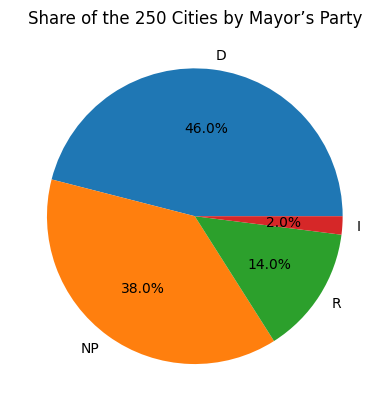

In [50]:
#output 3a

party_data = df['Party'].value_counts()
fig, ax = plt.subplots()
ax.set_title('Share of the 250 Cities by Mayor’s Party')
ax.pie(party_data.values, labels=party_data.index, autopct='%1.1f%%')
plt.show()


Democratic (D) mayors lead at 46% of the 250 cities, followed by Nonpartisan (NP) at 38%, Republican (R) at 14%, and Independent (I) at 2%, which is just 5 cities.

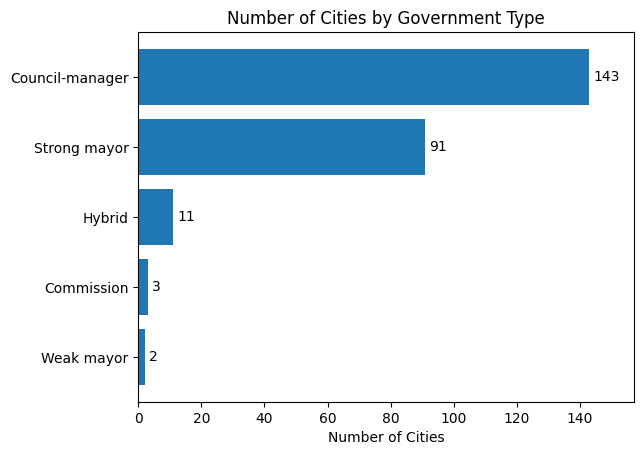

In [51]:
#output 3b

govern_data = df['Govern_Type'].value_counts()
plt.rcdefaults()
fig, ax = plt.subplots()
govern_types = govern_data.index
y_pos = np.arange(len(govern_types))
bars = ax.barh(y_pos, govern_data.values, align='center') #store horizontal bar container
ax.bar_label(bars, padding =3) # pass to bar_label
ax.set_xlim(0, max(govern_data.values)*1.1)
ax.set_yticks(y_pos)
ax.set_yticklabels(govern_types)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Number of Cities')
ax.set_title('Number of Cities by Government Type')

plt.show()

"Council-manager" government type is most common at 143 of the 250 cities, whereas the "Weak mayor" style only occurs in 2 cities as the least common. Note: the terms "City commission" and "Commission" were combined into one value "Commission" as I am treating them as identical government types.

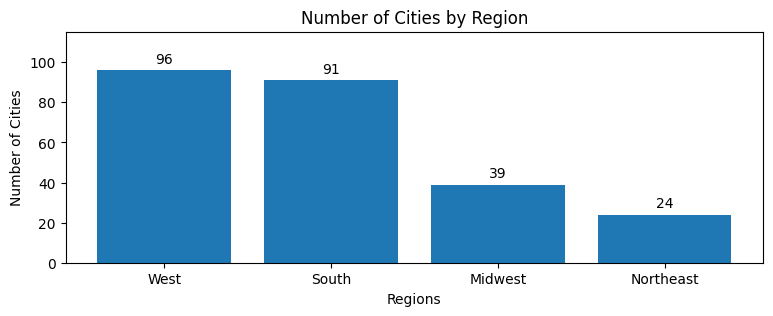

In [13]:
#output 3c

region_data = df['Region'].value_counts()
names = region_data.index
values = region_data.values
fig, ax = plt.subplots(1, 1, figsize=(9, 3))
ax.set_title('Number of Cities by Region')
ax.set_xlabel('Regions')
ax.set_ylabel('Number of Cities')
bars = ax.bar(names, values) #store vertical bar container
ax.bar_label(bars, padding =3) # pass to bar_label
ax.set_ylim(0, max(region_data.values)*1.2)
plt.show()

The West (96 cities) and South (91 cities) accounting for 187 of the 250  (nearly 75%), followed by Midwest with 39 and  Northeast with 24.


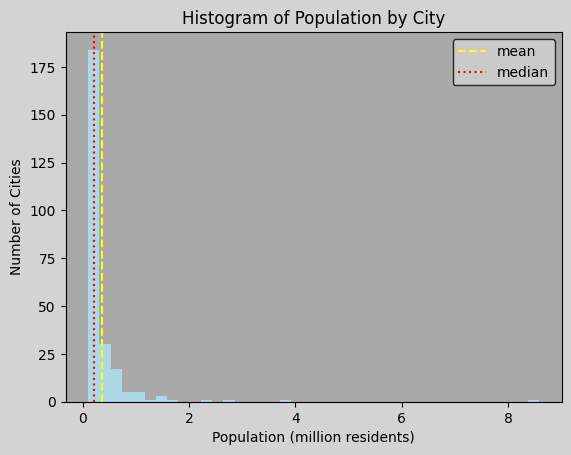

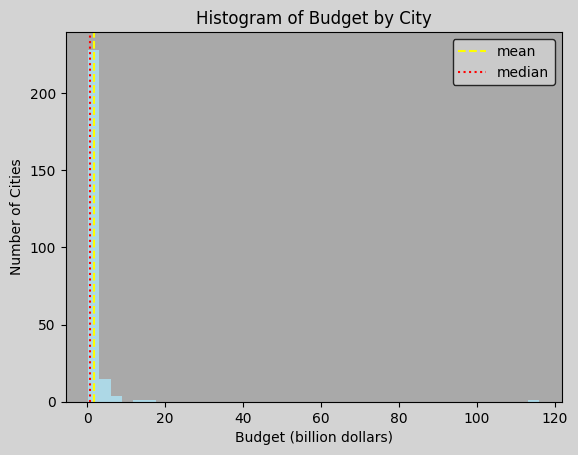

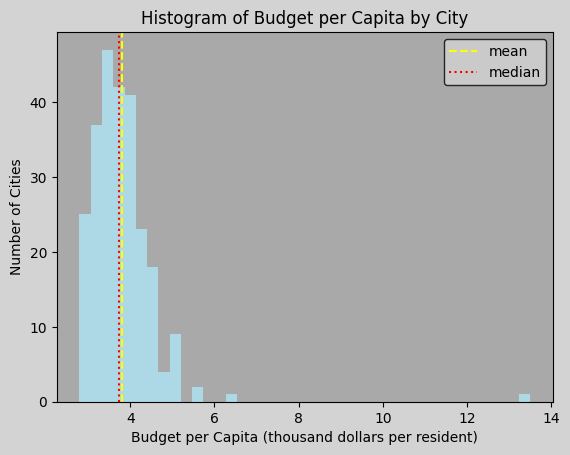

In [14]:
#output 4

measures = {
    'Population': ['million residents',1e-6],
    'Budget': ['billion dollars',1e-9],
    'Budget_per_Capita': ['thousand dollars per resident', 1e-3]
}


for k,v in measures.items():
    fig, ax = plt.subplots()
    ax.hist(df[k]*v[1], 40, facecolor='lightblue')
    ax.set_ylabel('Number of Cities')
    ax.set_xlabel(k.replace('_',' ')+' ('+v[0]+')')
    ax.set_title('Histogram of '+ k.replace('_',' ') +' by City')
    ax.axvline(x=df[k].mean()*v[1], color='yellow', label='mean', linestyle='--')
    ax.axvline(x=df[k].median()*v[1], color='red', label='median', linestyle=':')
    ax.set_facecolor('darkgrey')
    fig.set_facecolor('lightgrey')
    ax.legend(labelcolor="black", facecolor="lightgrey", edgecolor="black")
    plt.show()

The histogram of population shows us the tallest bar holds 184 cities, 74% of all cities, with the mean just right of the median, and a very long right tail.

The histogram of budget is very crowded, its tallest bar has 228 cities (over 90%) and (due to scaling) the mean and median appear to be on top of each other near the left edge, with a long and skinny right tail.

Regarding the budget per capita, the histogram depicts a wide spread, with the tallest bin having 47 cities, the mean and median nearly coinciding (consistent with the 2% difference seen in output 1) and a thin tail, ending in one far-right bar.

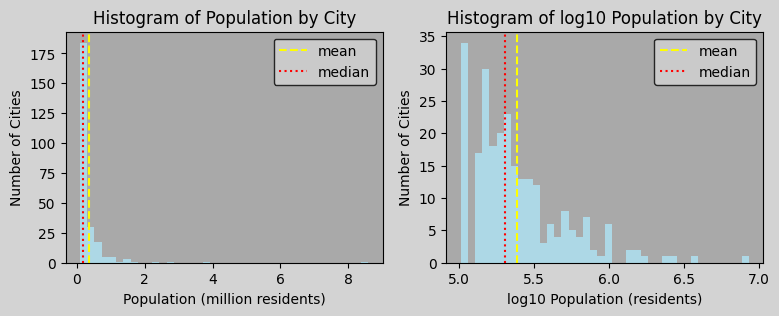

gap analysis for raw and log10 population


,mean,median,dif,% dif
Population,"359,287.93","202,010.00","157,277.93",77.9%
log10_Population,5.38,5.31,0.08,1.5%


In [15]:
#output 5

df['log10_Population'] = np.log10(df['Population'])
measures = {
    'Population': ['million residents',1e-6],
    'log10_Population': ['residents',1],
}
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for index, (k,v) in enumerate(measures.items()):
    ax[index].hist(df[k]*v[1], 40, facecolor='lightblue')
    ax[index].set_ylabel('Number of Cities')
    ax[index].set_xlabel(k.replace('_',' ')+' ('+v[0]+')')
    ax[index].set_title('Histogram of '+ k.replace('_',' ') +' by City')
    ax[index].axvline(x=df[k].mean()*v[1], color='yellow', label='mean', linestyle='--')
    ax[index].axvline(x=df[k].median()*v[1], color='red', label='median', linestyle=':')
    ax[index].set_facecolor('darkgrey')
    fig.set_facecolor('lightgrey')
    ax[index].legend(labelcolor="black", facecolor="lightgrey", edgecolor="black")
plt.show()
print('==='*30)
print('gap analysis for raw and log10 population')
log_gap_table = df[['Population', 'log10_Population']].agg(['mean','median']).T
log_gap_table['dif'] = log_gap_table['mean']-log_gap_table['median']
log_gap_table['% dif'] = log_gap_table['dif']/log_gap_table['median']
log_gap_table.style.format({'mean':'{:,.2f}', 'median':'{:,.2f}', 'dif':'{:,.2f}', '% dif':'{:,.1%}'})


Moving from the raw histogram to the log10 histogram, the gap between the mean and median fell from 77.9% to 1.5% of the median, the cities spread across many more bins, and the shape became more symmetric, though it still leans right.  

In [16]:
#output 6

print('==='*25)
print('skewness and kurtosis analysis over 4 measures')
skew_kurt_table = df[['Budget','Budget_per_Capita','Population', 'log10_Population']].agg(['skew','kurt']).T
kurt_conditions = [
    (skew_kurt_table['kurt']<0),
    #(skew_kurt_table['kurt']==0), #statistically unlikely
    (skew_kurt_table['kurt']>0)
]
skew_conditions = [
    (abs(skew_kurt_table['skew'])<.5),
    ((abs(skew_kurt_table['skew'])>=.5) & (abs(skew_kurt_table['skew'])<=1)),
    (abs(skew_kurt_table['skew'])>1)
]
#choices for different kurtosis conditions
#kurt_choices = ['platykurtic (light tailed)', 'mesokurtic (no tail)','leptokurtic (heavy tailed)']
kurt_choices = ['platykurtic (light tailed)','leptokurtic (heavy tailed)']
#choices for different skewness conditions
skew_choices = ['symmetric', 'moderately skewed','highly skewed']

skew_kurt_table['kurt_label'] = np.select(kurt_conditions, kurt_choices, default="Unknown")
skew_kurt_table['skew_label'] = np.select(skew_conditions, skew_choices, default="Unknown")
skew_kurt_table = skew_kurt_table[['skew','skew_label','kurt','kurt_label']]
skew_kurt_table.style.format({'skew':'{:,.4f}', 'kurt':'{:,.4f}'})



skewness and kurtosis analysis over 4 measures


,skew,skew_label,kurt,kurt_label
Budget,14.5153,highly skewed,221.6497,leptokurtic (heavy tailed)
Budget_per_Capita,6.2610,highly skewed,68.1054,leptokurtic (heavy tailed)
Population,8.9846,highly skewed,102.5072,leptokurtic (heavy tailed)
log10_Population,1.5067,highly skewed,3.1724,leptokurtic (heavy tailed)


My cutoff rules for skewness are <br>
<ul>
<li>absolute value less than .5 for a symmetric curve</li>
<li>between .5 and 1 for moderate skewness, and</li>
<li>highly skewed for any value greater than 1</li></ul>

Excess kurtosis (positive values) is leptokurtic (heavy tailed), whereas negative values are platykurtic (light tailed). The log10_Population (highly skewed, and heavy tailed) has a more moderate tail than Population (dropping from a kurtosis of 102.5072 to 3.1724), and the log10_Population decreased its skewness (dropping from 8.9846 to 1.5067), moving the skewness closer to the moderate range (.5 to 1) compared to the high skewness of Population values.

In [17]:
#output 7
measures_dict = {} # 1. start dictionary to save bands
print('==='*30)
print('std analysis for raw population')
std_table = df[['Population']].agg(['mean','std']).T
std_table['upper_edge'] = std_table['mean']+std_table['std']
std_table['lower_edge'] = std_table['mean']-std_table['std']
std_table_2 = std_table.style.format({'mean':'{:,.2f}', 'std':'{:,.2f}', 'upper_edge':'{:,.2f}', 'lower_edge':'{:,.2f}'})

display(std_table_2)

print('==='*30)
print('band analysis vs. empirical rule')
measures = ['Population','log10_Population','Budget_per_Capita']
bands = [1, 2, 3]

for x in measures:
    measure_std = df[x].std()
    measure_mean = df[x].mean()
    measures_dict[x]=[]
    for y in bands:
        distance_first_band = abs(df[x]-measure_mean)
        measures_dict[x].append((distance_first_band <= measure_std*y).mean())

measures_table = pd.DataFrame(measures_dict).T
measures_table = measures_table.rename(columns={0:'within 1 SD', 1:'within 2 SD', 2:'within 3 SD'})
measures_table.loc['Expected']=[.68,.95,.997]
measures_table_2 = measures_table.style.format('{:.1%}')
display(measures_table_2)

print('==='*30)
print('percentage point differences')
dif_df = measures_table - measures_table.loc['Expected']
dif_df = dif_df.drop(index='Expected')
dif_df_2 = dif_df.style.format('{:.1%}')
display(dif_df_2)



std analysis for raw population


,mean,std,upper_edge,lower_edge
Population,"359,287.93","657,301.55","1,016,589.47","-298,013.62"


band analysis vs. empirical rule


,within 1 SD,within 2 SD,within 3 SD
Population,95.6%,98.4%,98.4%
log10_Population,70.8%,96.0%,98.4%
Budget_per_Capita,87.2%,98.4%,99.6%
Expected,68.0%,95.0%,99.7%


percentage point differences


,within 1 SD,within 2 SD,within 3 SD
Population,27.6%,3.4%,-1.3%
log10_Population,2.8%,1.0%,-1.3%
Budget_per_Capita,19.2%,3.4%,-0.1%


log10_Population comes closest to the expected 68%-95%-99.7% empirical rule at the 1st and 2nd bands, while Population is furthest at 1 SD (27.6 percentage points) because the presence of large population cities inflates the standard deviation; at 3 SD, we see a negative gap, so more cities fall outside that band, which is consistent with heavy tails that we observed in output 6.


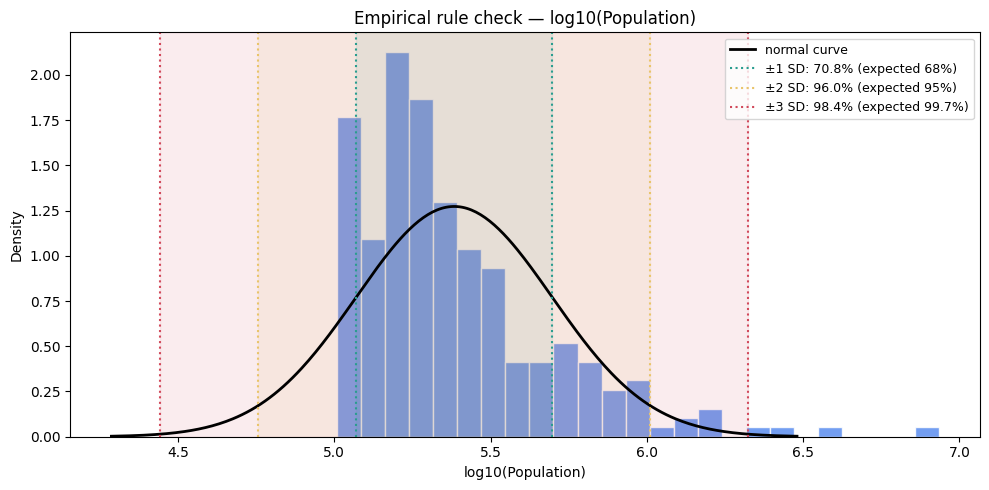

In [18]:
#output 8

x = df['log10_Population']
m = x.mean()
sd = x.std()
within = [((x - m).abs() <= k * sd).mean() * 100
for k in (1, 2, 3)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(
x,
bins=25,
density=True,
color="#5b8def",
edgecolor="white",
alpha=0.85,
)

grid = np.linspace(m - 3.5 * sd, m + 3.5 * sd, 300)
ax.plot(
    grid,
    stats.norm.pdf(grid, m, sd),
    color="black",
    lw=2,
    label="normal curve",
)

expected = [68, 95, 99.7]
band_colors = ("#2a9d8f", "#e9c46a", "#d1495b")
for k, c in zip((1, 2, 3), band_colors):
    ax.axvspan(m - k * sd, m + k * sd, color=c, alpha=0.10)
    ax.axvline(m - k * sd, color=c, ls=":")
    ax.axvline(
        m + k * sd,
        color=c,
        ls=":",
        label=(f"±{k} SD: {within[k-1]:.1f}% "
               f"(expected {expected[k-1]}%)"),
    )


ax.set_title("Empirical rule check — log10(Population)")
ax.set_xlabel("log10(Population)")
ax.set_ylabel("Density")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

For log10(Population), 70.8% of cities fall within one SD, 2.8 percentage points above the 68% that we expected, but only 98.4% fall within three SD, 1.3 points below the 99.7% expected, which leaves us with 1.6% of cities outside that third band against 0.3% for a bell curve.

In [19]:
#output 9

measures = ['Population','Budget','Budget_per_Capita']

for x in measures:
    measure_std = df[x].std()
    measure_mean = df[x].mean()
    df[x+'_Z'] = (df[x]-measure_mean)/measure_std

z_col =\
(abs(df[measures[0]+'_Z']) > 3) | (abs(df[measures[1]+'_Z']) > 3) | (abs(df[measures[2]+'_Z']) > 3)

print(z_col.sum())

display(df[z_col][['City','State', 'Population_Z', 'Budget_Z', 'Budget_per_Capita_Z']])

4


,City,State,Population_Z,Budget_Z,Budget_per_Capita_Z
0,New York,New York,12.513801,15.285419,11.429682
1,Los Angeles,California,5.339712,1.476363,-0.576674
2,Chicago,Illinois,3.609146,2.079086,2.986678
3,Houston,Texas,3.100597,0.659338,-1.181527


Of the four extreme cities, New York is the only city holding extremes on all three measures, with its budget the furthest out (z = 15.29), while Los Angeles, Chicago and Houston stand out on population exclusively (z = 5.34, 3.61 and 3.10).

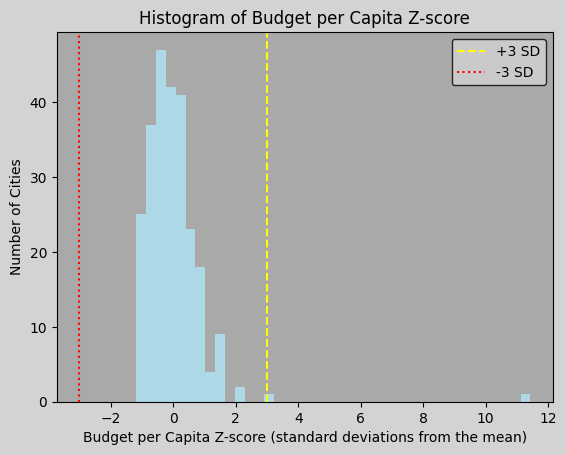

In [20]:
#output #10

measure = 'Budget_per_Capita_Z'
fig, ax = plt.subplots()
ax.hist(df[measure], 40, facecolor='lightblue')
ax.set_ylabel('Number of Cities')
ax.set_xlabel(measure.replace('_',' ')+'-score (standard deviations from the mean)')
ax.set_title('Histogram of '+ measure.replace('_',' ')+'-score')
ax.axvline(x=3, color='yellow', label='+3 SD', linestyle='--')
ax.axvline(x=-3, color='red', label='-3 SD', linestyle=':')
ax.set_facecolor('darkgrey')
fig.set_facecolor('lightgrey')
ax.legend(labelcolor="black", facecolor="lightgrey", edgecolor="black")
plt.show()

We see the majority of cities cluster together between about −1.2 and +1.7 standard deviations, followed by a long right tail stretching out to New York at about 11.4.

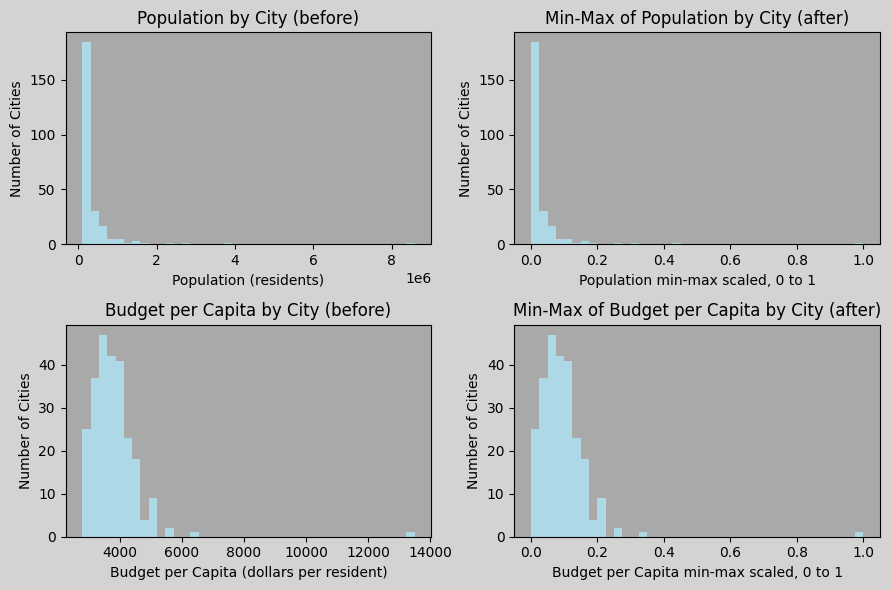

In [21]:
#output 11

measures = ['Population','Budget_per_Capita']
fig, ax = plt.subplots(2, 2, figsize=(9, 6))
for index, x in enumerate(measures):
    min_measure = df[x].min()
    max_measure = df[x].max()
    value_range = max_measure - min_measure
    df[x+'_MM'] = (df[x]-min_measure)/value_range
    ax[index,0].hist(df[x], 40, facecolor='lightblue')
    ax[index,0].set_ylabel('Number of Cities')
    ax[index,0].set_xlabel(x+' (residents)' if x=='Population' \
                           else (x.replace('_',' ')+' (dollars per resident)'))
    ax[index,0].set_title(x.replace('_',' ') +' by City (before)')
    ax[index,0].set_facecolor('darkgrey')

    ax[index,1].hist(df[x+'_MM'], 40, facecolor='lightblue')
    ax[index,1].set_ylabel('Number of Cities')
    ax[index,1].set_xlabel(x.replace('_',' ')+' min-max scaled, 0 to 1')
    ax[index,1].set_title('Min-Max of '+ x.replace('_',' ') +' by City (after)')
    ax[index,1].set_facecolor('darkgrey')
    fig.set_facecolor('lightgrey')
plt.tight_layout()
plt.show()

Min-max scaling represents each measure on a 0-to-1 scale (the raw Population axis ran to New York, the most populous city at about 8.6 million residents), but both the Population and Budget per Capita histograms look identical before and after.

In [22]:
#output 12

target_cities =['New York', 'Chicago', 'Boise', 'Hesperia']
filtered_df = df[df['City'].isin(target_cities)]\
 [['City','Population','Population_Z','Population_MM',\
   'Budget_per_Capita','Budget_per_Capita_Z','Budget_per_Capita_MM',]]
filtered_df.style.format({'Population':'{:,.0f}', 'Population_MM':'{:,.2f}',\
                          'Population_Z':'{:,.2f}', 'Budget_per_Capita':'{:,.2f}',\
                          'Budget_per_Capita_Z':'{:,.2f}','Budget_per_Capita_MM':'{:,.2f}'})

,City,Population,Population_Z,Population_MM,Budget_per_Capita,Budget_per_Capita_Z,Budget_per_Capita_MM
0,New York,"8,584,629",12.51,1.00,"13,500.87",11.43,1.00
2,Chicago,"2,731,585",3.61,0.31,"6,333.32",2.99,0.33
96,Boise,"238,429",-0.18,0.02,"3,123.99",-0.79,0.03
246,Hesperia,"102,605",-0.39,0.00,"2,815.26",-1.16,0.00


The min-max value shows where a city sits relative to the smallest and largest (0 to 1), while the z-score shows the number of standard deviations it sits from the mean, which explains why Hesperia and Boise (population z-scores of −0.39 and −0.18) read as below average and Chicago and New York (population z-scores of 3.61 and 12.51) stand out as extreme cities.

In [23]:
#output 13

df_remove = df[(abs(df['Budget_per_Capita_Z']) >3)]
print(f'Cities removed (|z| > 3 on Budget_per_Capita): {len(df_remove)}')
display(df_remove[['City','State','Budget_per_Capita','Budget_per_Capita_Z']])
print('=='*50)

df_z = df[~df['State_City'].isin(df_remove['State_City'])].copy()
df_z.head()

Cities removed (|z| > 3 on Budget_per_Capita): 1


,City,State,Budget_per_Capita,Budget_per_Capita_Z
0,New York,New York,13500.87,11.429682


,State_City,Population,Budget,Gender,Begin_Term,End_Term,Govern_Type,foo1,foo2,City,...,Budget_per_Capita,Bloc,City_Size,Budget_Size,log10_Population,Population_Z,Budget_Z,Budget_per_Capita_Z,Population_MM,Budget_per_Capita_MM
1,"Los Angeles, California",3869089,12800000000,F,2022,2026,Strong mayor,Yes,Yes,Los Angeles,...,3308.27,Democratic caucus,Major,Major,6.587609,5.339712,1.476363,-0.576674,0.444105,0.047962
2,"Chicago, Illinois",2731585,17300000000,M,2023,2027,Strong mayor,Yes,No,Chicago,...,6333.32,Democratic caucus,Major,Major,6.436415,3.609146,2.079086,2.986678,0.310010,0.330516
3,"Houston, Texas",2397315,6700000000,M,2024,2028,Strong mayor,No,No,Houston,...,2794.79,Democratic caucus,Major,Major,6.379725,3.100597,0.659338,-1.181527,0.270604,0.000000
4,"Philadelphia, Pennsylvania",1574281,6400000000,F,2024,2028,Strong mayor,Yes,Yes,Philadelphia,...,4065.35,Democratic caucus,Major,Major,6.197082,1.848456,0.619157,0.315127,0.173580,0.118676
5,"Phoenix, Arizona",1665481,5600000000,F,2019,2023,Council-manager,No,Yes,Phoenix,...,3362.39,Democratic caucus,Major,Major,6.221540,1.987205,0.512006,-0.512924,0.184332,0.053017


The |z| > 3 rule on Budget per Capita removes only New York (z = 11.43), which is 0.4% of cities and leaves 249, while Chicago (2.99) barely remains, and Los Angeles and Houston stay because despite their extreme population size, their budget per capita z score prevents removal.

In [24]:
#output 14

q1 = df['Budget_per_Capita'].quantile(.25)
q3 = df['Budget_per_Capita'].quantile(.75)
iqr = q3-q1

print(f'lower fence: {q1-1.5*iqr:,.2f}')
print(f'upper fence: {q3+1.5*iqr:,.2f}')
print('=='*50)
df_remove = df[((df['Budget_per_Capita'] <(q1-1.5*iqr)))\
                | \
                (df['Budget_per_Capita'] >(q3+1.5*iqr))]
print(f'Cities removed for budget per capita (values outside Q1 − 1.5 × IQR and Q3 + 1.5 × IQR): {len(df_remove)}')
display(df_remove[['City','State','Budget_per_Capita','Budget_per_Capita_Z']])

df_iqr = df[~df['State_City'].isin(df_remove['State_City'])].copy()
print('=='*50)
df_iqr.head()

lower fence: 2,178.74
upper fence: 5,254.96
Cities removed for budget per capita (values outside Q1 − 1.5 × IQR and Q3 + 1.5 × IQR): 4


,City,State,Budget_per_Capita,Budget_per_Capita_Z
0,New York,New York,13500.87,11.429682
2,Chicago,Illinois,6333.32,2.986678
6,San Antonio,Texas,5720.40,2.264690
15,Columbus,Ohio,5536.01,2.047488


,State_City,Population,Budget,Gender,Begin_Term,End_Term,Govern_Type,foo1,foo2,City,...,Budget_per_Capita,Bloc,City_Size,Budget_Size,log10_Population,Population_Z,Budget_Z,Budget_per_Capita_Z,Population_MM,Budget_per_Capita_MM
1,"Los Angeles, California",3869089,12800000000,F,2022,2026,Strong mayor,Yes,Yes,Los Angeles,...,3308.27,Democratic caucus,Major,Major,6.587609,5.339712,1.476363,-0.576674,0.444105,0.047962
3,"Houston, Texas",2397315,6700000000,M,2024,2028,Strong mayor,No,No,Houston,...,2794.79,Democratic caucus,Major,Major,6.379725,3.100597,0.659338,-1.181527,0.270604,0.000000
4,"Philadelphia, Pennsylvania",1574281,6400000000,F,2024,2028,Strong mayor,Yes,Yes,Philadelphia,...,4065.35,Democratic caucus,Major,Major,6.197082,1.848456,0.619157,0.315127,0.173580,0.118676
5,"Phoenix, Arizona",1665481,5600000000,F,2019,2023,Council-manager,No,Yes,Phoenix,...,3362.39,Democratic caucus,Major,Major,6.221540,1.987205,0.512006,-0.512924,0.184332,0.053017
7,"San Diego, California",1406106,6837570000,M,2020,2024,Strong mayor,Yes,No,San Diego,...,4862.77,Democratic caucus,Major,Major,6.148018,1.592599,0.677764,1.254446,0.153755,0.193159


The IQR rule removes three more cities than the z rule (4 versus 1), because New York’s extreme value inflates the standard deviation, masking Chicago, San Antonio and Columbus from the |z| > 3 cutoff, while the quartile-based fences resist that stretching.

In [25]:
#output 15

print('Budget per Capita Comparison Chart')
raw_agg = df[['Budget_per_Capita']].agg(['count','mean', 'median', 'std', 'min','max', 'skew', 'kurt']).T
dfz_agg = df_z[['Budget_per_Capita']].agg(['count','mean', 'median', 'std', 'min','max', 'skew', 'kurt']).T
iqr_agg = df_iqr[['Budget_per_Capita']].agg(['count','mean', 'median', 'std', 'min','max', 'skew', 'kurt']).T
before_after_table = pd.concat([raw_agg, dfz_agg, iqr_agg], axis=0, keys=['Original','z rule','IQR rule']).droplevel(1)
before_after_table.style.format({'count':'{:,.0f}', 'mean':'{:,.2f}', 'median':'{:,.2f}', \
                                         'std':'{:,.2f}', 'min':'{:,.2f}', 'max':'{:,.2f}', 'skew':'{:,.2f}', 'kurt':'{:,.2f}'})

Budget per Capita Comparison Chart


,count,mean,median,std,min,max,skew,kurt
Original,250,"3,797.83","3,724.43",848.93,"2,794.79","13,500.87",6.26,68.11
z rule,249,"3,758.86","3,723.44",585.18,"2,794.79","6,333.32",0.86,1.31
IQR rule,246,"3,733.20","3,706.43",538.81,"2,794.79","5,171.67",0.47,-0.24


By removing 1 city (z rule) or 4 cities (IQR rule) out of 250 we see that Budget per Capita skewness drops from 6.26 to 0.86 and then 0.47, just as the standard deviation drops from 848.93 to 585.18 and 538.81, and the fact that the minimum remained unchanged at $2,794.79 demonstrates that the removed cities were at the high end.

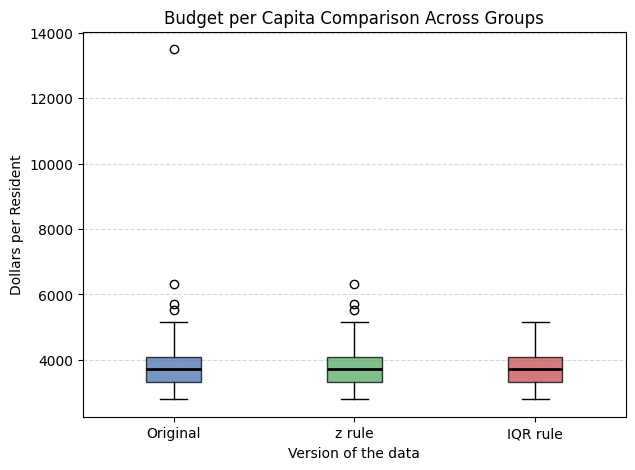

In [26]:
#output 16a

m = 'Budget_per_Capita'
group_a = df[m]
group_b = df_z[m]
group_c = df_iqr[m]

fig, ax = plt.subplots(figsize=(7,5))
bp = ax.boxplot(
    [group_a, group_b, group_c],
    tick_labels=["Original", "z rule", "IQR rule"],
    patch_artist=True,  # Required to fill boxes with color
)

# Customize box fill colors
colors = ["#4C72B0", "#55A868", "#C44E52"]
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

# Customize median line
for median in bp["medians"]:
    median.set(color="black", linewidth=2)

ax.set_title("Budget per Capita Comparison Across Groups")
ax.set_ylabel("Dollars per Resident")
ax.set_xlabel("Version of the data")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()



We observe the dots above the top whisker reducing from 4 in the Original (New York, Chicago, San Antonio and Columbus) to 3 under the z rule to 0 under the IQR rule, while the boxes and medians remain virtually unchanged.

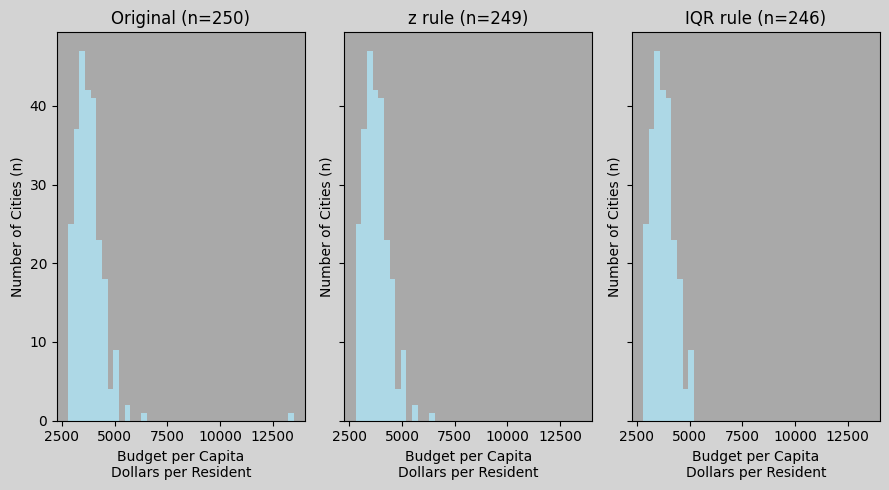

In [27]:
#output 16b

m = 'Budget_per_Capita'
group_a = df[m]
group_b = df_z[m]
group_c = df_iqr[m]
low = group_a.min()
high = group_a.max()
group_dict = { 'Original (n='+str(len(group_a))+')':group_a,
              'z rule (n='+str(len(group_b))+')':group_b,
               'IQR rule (n='+str(len(group_c))+')':group_c}
fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(9, 5)) #
for i, (k,v) in enumerate(group_dict.items()):
    ax[i].hist(v, np.linspace(low, high, 41), facecolor='lightblue')
    ax[i].set_ylabel('Number of Cities (n)')
    ax[i].set_xlabel(m.replace('_',' ') + '\nDollars per Resident')
    ax[i].set_title(k)
    ax[i].set_facecolor('darkgrey')
fig.set_facecolor('lightgrey')
plt.tight_layout()
plt.show()


Both rules filter out only high-end cities, preserving the 47-city peak, while the right edge of the data shrinks from about \$13,500 (New York's Budget per Capita) to about \$5,200 under the IQR rule, roughly 38% of the original.

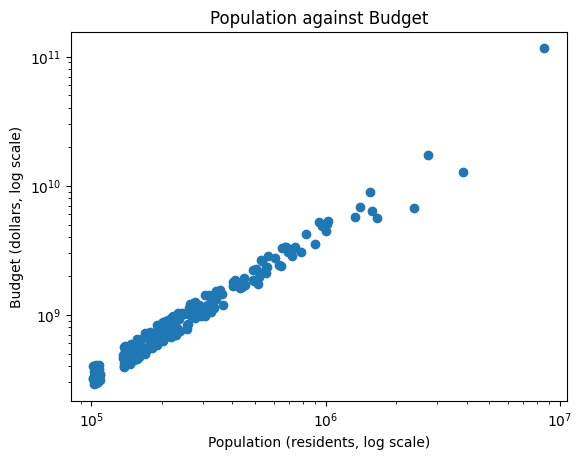

Correlation with New York: 0.910
Correlation without New York: 0.952


In [28]:
#output 17

fig, ax = plt.subplots()
ax.set_xscale('log')
ax.set_yscale('log')
ax.scatter(df['Population'], df['Budget'])
ax.set_ylabel('Budget (dollars, log scale)')
ax.set_xlabel('Population (residents, log scale)')
ax.set_title('Population against Budget')
plt.show()

df_no_ny = df[df['City'] != 'New York']
print(f'Correlation with New York: {df['Population'].corr(df['Budget']):.3f}')
print(f'Correlation without New York: {df_no_ny['Population'].corr(df_no_ny['Budget']):.3f}')

We observe budget rising roughly in proportion to population (a straight band on the log scales), with a raw-value correlation of 0.91 that rises to 0.95 without the outlier New York that does not fit the pattern of the other cities.

In [29]:
#output to file
# I chose to use the IQR rule dataset as my us_cities_no_outliers.csv file so
# it leaves zero outliers in the box-plot rule, where the z rule leaves 3.
#
# Note: The z-score and min-max columns inside us_cities_no_outliers.csv
# were calculated on all 250 cities, before any removal. So they’re measured
# against the original mean, standard deviation, minimum and maximum, AND NOT
# against the 246 remaining cities.

df.to_csv('us_cities_with_stats.csv', index=False)
df_iqr.to_csv('us_cities_no_outliers.csv', index=False)

print("Sample line from us_cities_with_stats.csv:")
with open('us_cities_with_stats.csv', 'r') as fh:
    line_fl_raw = [raw_line for raw_line in fh if raw_line.startswith('"Fort Lauderdale')]
print(line_fl_raw[0])

print("Sample line from us_cities_no_outliers.csv:")
with open('us_cities_no_outliers.csv', 'r') as fh:
    line_fl_raw = [raw_line for raw_line in fh if raw_line.startswith('"Fort Lauderdale')]
print(line_fl_raw[0])

df2 = pd.read_csv('us_cities_with_stats.csv')
print("The us_cities_with_stats.csv extracted into a dataframe:")
print(df2.shape)
print(df2.index[:2])
print(df2['State_City'].iloc[0])

df2 = pd.read_csv('us_cities_no_outliers.csv')
print("The us_cities_no_outliers.csv extracted into a dataframe:")
print(df2.shape)
print(df2.index[:2])
print(df2['State_City'].iloc[0])

Sample line from us_cities_with_stats.csv:
"Fort Lauderdale, Florida",188677,735510000,M,2024,2028,Council-manager,No,No,Fort Lauderdale,Florida,Dean Trantalis,,D,South,3898.25,Democratic caucus,Small,Small,5.275718962264126,-0.2595626450204715,-0.13953618824647268,0.11829169171847771,0.010237545525973456,0.10306853675668404

Sample line from us_cities_no_outliers.csv:
"Fort Lauderdale, Florida",188677,735510000,M,2024,2028,Council-manager,No,No,Fort Lauderdale,Florida,Dean Trantalis,,D,South,3898.25,Democratic caucus,Small,Small,5.275718962264126,-0.2595626450204715,-0.13953618824647268,0.11829169171847771,0.010237545525973456,0.10306853675668404

The us_cities_with_stats.csv extracted into a dataframe:
(250, 25)
RangeIndex(start=0, stop=2, step=1)
New York, New York
The us_cities_no_outliers.csv extracted into a dataframe:
(246, 25)
RangeIndex(start=0, stop=2, step=1)
Los Angeles, California


In [30]:
#checking output files
check_stats = pd.read_csv('us_cities_with_stats.csv')
assert check_stats.shape == (250, 25), 'Error! Shape of (250, 25) expected.'
check_no_outliers = pd.read_csv('us_cities_no_outliers.csv')
assert check_no_outliers.shape == (246, 25), 'Error! Shape of (246, 25) expected.'

In [31]:
# Part 5b - cross-tab of City_Size × Budget_Size

df_cross_tab = pd.crosstab(df['City_Size'], df['Budget_Size']).iloc[::-1, ::-1]

display(df_cross_tab)
print('==='*30)
print("The city whose City_Size is Large and Budget_Size is Major: ", end='')
print(df[((df['City_Size'] == 'Large') & (df['Budget_Size'] == 'Major'))][['City','State']].to_string(header=False, index=False))
print('==='*30)
print("The city whose City_Size is Major and Budget_Size is Large: ", end='')
print(df[((df['City_Size'] == 'Major') & (df['Budget_Size'] == 'Large'))][['City','State']].to_string(header=False, index=False))
print('==='*30)

Budget_Size,Major,Large,Medium,Small,Tiny
City_Size,,,,,
Major,11,1,0,0,0
Large,1,24,2,0,0
Medium,0,1,43,9,0
Small,0,0,3,81,7
Tiny,0,0,0,14,53


The city whose City_Size is Large and Budget_Size is Major: Columbus Ohio
The city whose City_Size is Major and Budget_Size is Large: Austin Texas


212 of 250 cities (84.8%) match both in population and budget tiers, led by Small × Small (81 cities), while the remaining 38 cities split evenly, 19 with a higher budget tier (like Columbus) and 19 with a lower one (such as Austin).

In [32]:
#part 5-c City_Size_Q

labels = ['Tiny','Small','Medium','Large','Major']
df['City_Size_Q']=pd.qcut(df['Population'], 5, labels=labels)
display(df['City_Size_Q'].value_counts(sort=False).sort_index(ascending=False))

print('==='*30)
print('The 80th percentile of the population: ', end='')
print(f'{df['Population'].quantile(0.8):,.0f}')

,count
City_Size_Q,
Major,50
Large,50
Medium,50
Small,50
Tiny,50


The 80th percentile of the population: 403,718


Quintile tiers hold the city count constant at 50 each, so the Major tier starts at roughly 400k residents, 60% below the fixed 1,000,000 cutoff, and holds 50 cities where the fixed Major tier holds only 12.

Measures by Bloc


,Cities,Population,Budget
Bloc,,,
Democratic caucus,0.86,0.884141,0.907708
Republican,0.14,0.115859,0.092292


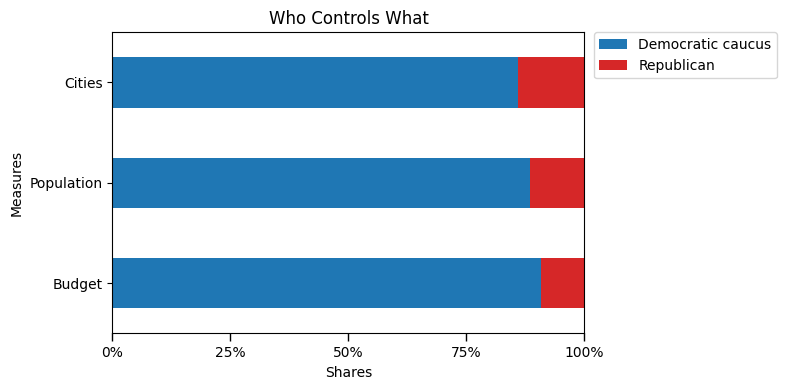

In [33]:
#part 6a: Project A: who really controls the budget and the population?

total_budget = df['Budget'].sum()
total_population = df['Population'].sum()
budget_by_bloc = df.groupby('Bloc')['Budget'].sum()/total_budget
pop_by_bloc = df.groupby('Bloc')['Population'].sum()/total_population
cities_by_bloc = df['Bloc'].value_counts(normalize=True)

control_dict = {
    'Cities': cities_by_bloc,
    'Population': pop_by_bloc,
    'Budget': budget_by_bloc
}

print('Measures by Bloc')
df_control = pd.DataFrame(control_dict)
display(df_control)

df_control = df_control.T
color_map = {
    'Republican': '#d62728',
    'Democratic caucus': '#1F77B4'
}

ax = df_control.plot.barh(stacked=True, color=color_map, title='Who Controls What', figsize=(8,4))
ax.set_xlim(0,1.0)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0,decimals=0))
ax.tick_params(axis='x', which='major', bottom=True, length=6, width=1)
ax.set_xlabel('Shares')
ax.set_ylabel('Measures')
ax.invert_yaxis()
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()


The Republican bloc holds a minority, 14% of the cities, but only 11.6% of the population and 9.2% of the budget, which means the Republican led cities are smaller and spend less per resident in contrast to the Democratic caucus cities.

Measures by Party


,Cities,Population,Budget
Party,,,
D,0.46,0.676442,0.750962
I,0.02,0.016328,0.012350
NP,0.38,0.191372,0.144395
R,0.14,0.115859,0.092292


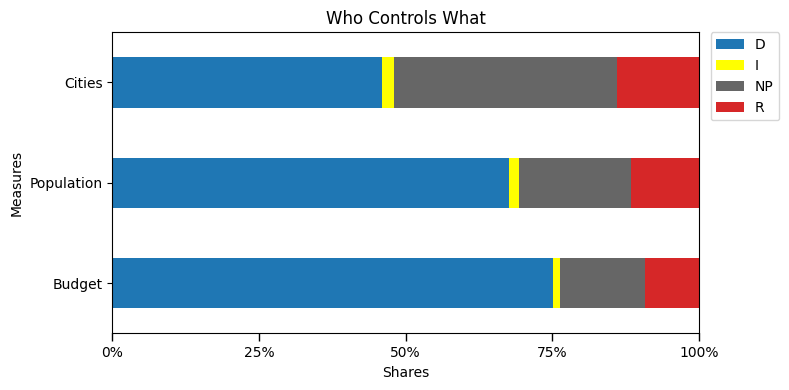

In [34]:
#part 6b: who really controls the budget and the population by party?

total_budget = df['Budget'].sum()
total_population = df['Population'].sum()
budget_by_party = df.groupby('Party')['Budget'].sum()/total_budget
pop_by_party = df.groupby('Party')['Population'].sum()/total_population
cities_by_party = df['Party'].value_counts(normalize=True)

control_dict = {
    'Cities': cities_by_party,
    'Population': pop_by_party,
    'Budget': budget_by_party
}

df_control = pd.DataFrame(control_dict)
print('Measures by Party')
display(df_control)

df_control = df_control.T
color_map = {
    'R': '#d62728',
    'D': '#1F77B4',
    'NP': '#666666',
    'I': 'yellow'
}

ax = df_control.plot.barh(stacked=True, color=color_map, title='Who Controls What', figsize=(8,4))
ax.set_xlim(0,1.0)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0,decimals=0))
ax.tick_params(axis='x', which='major', bottom=True, length=6, width=1)
ax.set_xlabel('Shares')
ax.set_ylabel('Measures')
ax.invert_yaxis()
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()

The Democrats hold 75.1% of the budget, and combined the Independents and Nonpartisans add 15.7 points, which brings the total of the Democratic caucus to 90.8%.

In [35]:
# Part 6c - Project B - control by city tier
# cross-tab of City_Size × Bloc


print('Republican share within each City_Size tier')
print('=='*22)
tier_cities = pd.crosstab(df['City_Size'], df['Bloc'], normalize='index').iloc[::-1, ::]
tier_pop = pd.crosstab(df['City_Size'], df['Bloc'], normalize='index', values=df['Population'], aggfunc='sum').iloc[::-1, ::]
tier_budget = pd.crosstab(df['City_Size'], df['Bloc'], normalize='index', values=df['Budget'], aggfunc='sum').iloc[::-1, ::]
tier_dict = {
    'Cities': tier_cities['Republican'],
    'Population': tier_pop['Republican'],
    'Budget': tier_budget['Republican']
}
df_control = pd.DataFrame(tier_dict)
display(df_control)

total_budget = df['Budget'].sum()
total_budget_tier_share = (df.groupby('City_Size', observed=True)['Budget'].sum()/total_budget).iloc[::-1]
print('=='*22)
print('Total budget share within each City_Size tier')
print('=='*22)
display(total_budget_tier_share)
print('=='*25)
total_pop = df['Population'].sum()
total_pop_tier_share = (df.groupby('City_Size', observed=True)['Population'].sum()/total_pop).iloc[::-1]
print('Total population share within each City_Size tier')
print('=='*25)
display(total_pop_tier_share)


Republican share within each City_Size tier


,Cities,Population,Budget
City_Size,,,
Major,0.166667,0.083737,0.054666
Large,0.111111,0.098023,0.082044
Medium,0.132075,0.141148,0.140989
Small,0.153846,0.150557,0.151648
Tiny,0.134328,0.137272,0.136114


Total budget share within each City_Size tier


,Budget
City_Size,
Major,0.452210
Large,0.184542
Medium,0.155950
Small,0.143399
Tiny,0.063900


Total population share within each City_Size tier


,Population
City_Size,
Major,0.313452
Large,0.203195
Medium,0.196984
Small,0.194118
Tiny,0.092251


Republican control is strongest in the Small tier (15.1% of its population, 15.2% of its budget), which holds only 19.4% of the total population and 14.3% of the total budget, since most of the people and money sit in the Major tier (31.3% and 45.2%), where the Republican share falls to only 5.5% of the budget.

Measures of 249 Cities (New York removed)


,Cities,Population,Budget
Bloc,,,
Democratic caucus,0.859438,0.871898,0.875138
Republican,0.140562,0.128102,0.124862


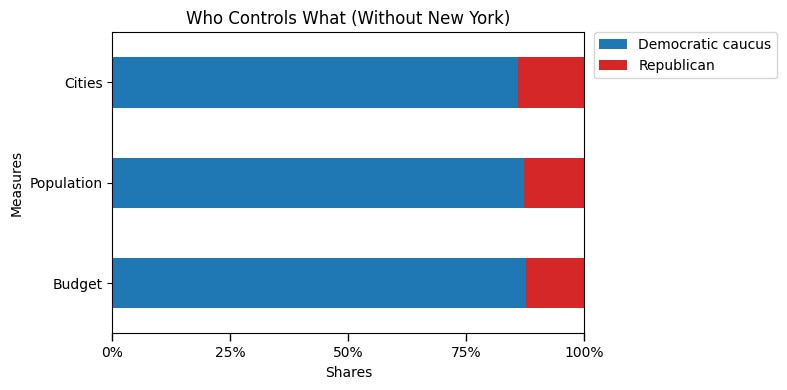

lower fence: 2,178.74
upper fence: 5,254.96
Cities removed for budget per capita (values outside Q1 − 1.5 × IQR and Q3 + 1.5 × IQR): 4


,City,State,Budget_per_Capita,Budget_per_Capita_Z
0,New York,New York,13500.87,11.429682
2,Chicago,Illinois,6333.32,2.986678
6,San Antonio,Texas,5720.40,2.264690
15,Columbus,Ohio,5536.01,2.047488


Measures of 246 Cities (New York, Chicago, San Antonio, and Columbus removed)


,Cities,Population,Budget
Bloc,,,
Democratic caucus,0.857724,0.863105,0.861961
Republican,0.142276,0.136895,0.138039


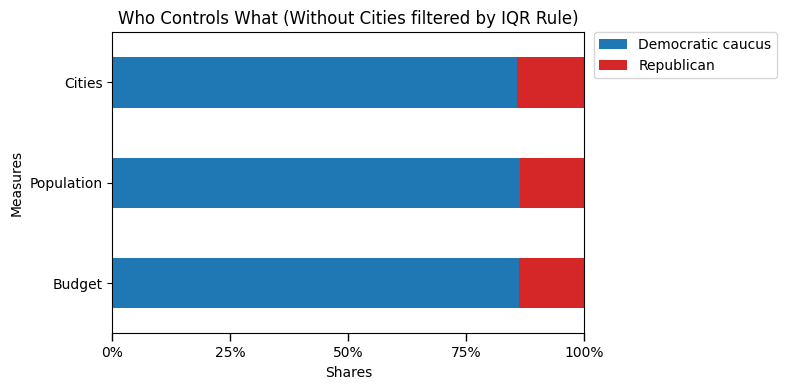

In [36]:
#part 6d: Project C: "the New York effect"

df_no_ny = df[df['City'] != 'New York']

total_budget_no_ny = df_no_ny['Budget'].sum()
total_population_no_ny = df_no_ny['Population'].sum()
budget_by_bloc_no_ny = df_no_ny.groupby('Bloc')['Budget'].sum()/total_budget_no_ny
pop_by_bloc_no_ny = df_no_ny.groupby('Bloc')['Population'].sum()/total_population_no_ny
cities_by_bloc_no_ny = df_no_ny['Bloc'].value_counts(normalize=True)

control_dict = {
    'Cities': cities_by_bloc_no_ny,
    'Population': pop_by_bloc_no_ny,
    'Budget': budget_by_bloc_no_ny
}

df_no_ny_control = pd.DataFrame(control_dict)
print('Measures of 249 Cities (New York removed)')
display(df_no_ny_control)
print('==' *50)
df_no_ny_control = df_no_ny_control.T
color_map = {
    'Republican': '#d62728',
    'Democratic caucus': '#1F77B4'
}

ax = df_no_ny_control.plot.barh(stacked=True, color=color_map, title='Who Controls What (Without New York)', figsize=(8,4))
ax.set_xlim(0,1.0)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0,decimals=0))
ax.tick_params(axis='x', which='major', bottom=True, length=6, width=1)
ax.set_xlabel('Shares')
ax.set_ylabel('Measures')
ax.invert_yaxis()
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()

print('==' *50)
#regenerating IQR filtered df

q1 = df['Budget_per_Capita'].quantile(.25)
q3 = df['Budget_per_Capita'].quantile(.75)
iqr = q3-q1

print(f'lower fence: {q1-1.5*iqr:,.2f}')
print(f'upper fence: {q3+1.5*iqr:,.2f}')
print('==' *50)

df_remove = df[((df['Budget_per_Capita'] <(q1-1.5*iqr)))\
                | \
                (df['Budget_per_Capita'] >(q3+1.5*iqr))]
print(f'Cities removed for budget per capita (values outside Q1 − 1.5 × IQR and Q3 + 1.5 × IQR): {len(df_remove)}')
display(df_remove[['City','State','Budget_per_Capita','Budget_per_Capita_Z']])
print('==' *50)
df_iqr = df[~df['State_City'].isin(df_remove['State_City'])].copy()

total_budget_iqr = df_iqr['Budget'].sum()
total_population_iqr = df_iqr['Population'].sum()
budget_by_bloc_iqr = df_iqr.groupby('Bloc')['Budget'].sum()/total_budget_iqr
pop_by_bloc_iqr = df_iqr.groupby('Bloc')['Population'].sum()/total_population_iqr
cities_by_bloc_iqr = df_iqr['Bloc'].value_counts(normalize=True)

control_dict = {
    'Cities': cities_by_bloc_iqr,
    'Population': pop_by_bloc_iqr,
    'Budget': budget_by_bloc_iqr
}

df_iqr_control = pd.DataFrame(control_dict)
print('Measures of 246 Cities (New York, Chicago, San Antonio, and Columbus removed)')
display(df_iqr_control)
print('==' *50)
df_iqr_control = df_iqr_control.T
color_map = {
    'Republican': '#d62728',
    'Democratic caucus': '#1F77B4'
}

ax = df_iqr_control.plot.barh(stacked=True, color=color_map, title='Who Controls What (Without Cities filtered by IQR Rule)', figsize=(8,4))
ax.set_xlim(0,1.0)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0,decimals=0))
ax.tick_params(axis='x', which='major', bottom=True, length=6, width=1)
ax.set_xlabel('Shares')
ax.set_ylabel('Measures')
ax.invert_yaxis()
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()



Removing New York raises the Republican budget share 3.3 points from 9.2% to 12.5%, and filtering out all four IQR outliers lifts it up to 13.8% (4.6 points in total), almost matching its 14.2% share of the cities.

Bloc    Democratic caucus   Republican  Difference
mean          3816.159814  3685.219714    130.9401
median        3731.190000  3655.600000     75.5900


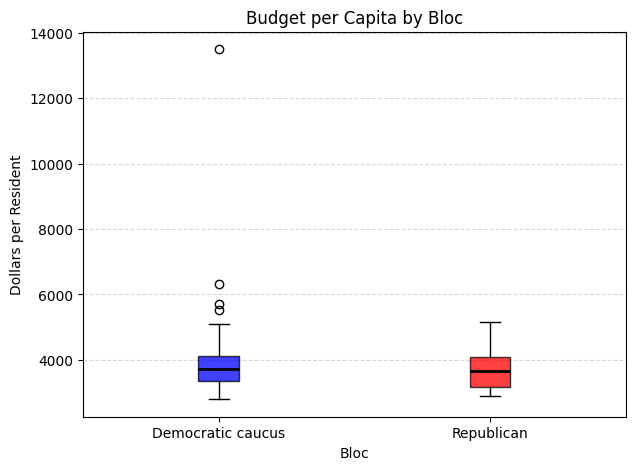

In [37]:
#part 6e: Project D: Who controls the dollars per resident?

per_cap_by_bloc = df.groupby('Bloc')['Budget_per_Capita'].agg(['mean','median']).T
per_cap_by_bloc['Difference']=per_cap_by_bloc['Democratic caucus']-per_cap_by_bloc['Republican']
print(f'{per_cap_by_bloc}')

m = 'Budget_per_Capita'
group_a = df[df['Bloc'] == 'Democratic caucus'][m]
group_b = df[df['Bloc'] == 'Republican'][m]

fig, ax = plt.subplots(figsize=(7,5))
bp = ax.boxplot(
    [group_a, group_b],
    tick_labels=['Democratic caucus', 'Republican'],
    patch_artist=True,  # Required to fill boxes with color
)

# Customize box fill colors
colors = ['blue', 'red']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

# Customize median line
for median in bp['medians']:
    median.set(color='black', linewidth=2)

ax.set_title('Budget per Capita by Bloc')
ax.set_ylabel('Dollars per Resident')
ax.set_xlabel('Bloc')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()





A typical city in the Democratic caucus spends more per resident than its counterpart in the Republican bloc (\$3,731.19 versus \$3,655.60 at the median, a gap of \$75.59), so the difference is not isolated in the means.

        Cities  Population    Budget
Gender                              
F        0.316    0.332419  0.270131
M        0.684    0.667581  0.729869


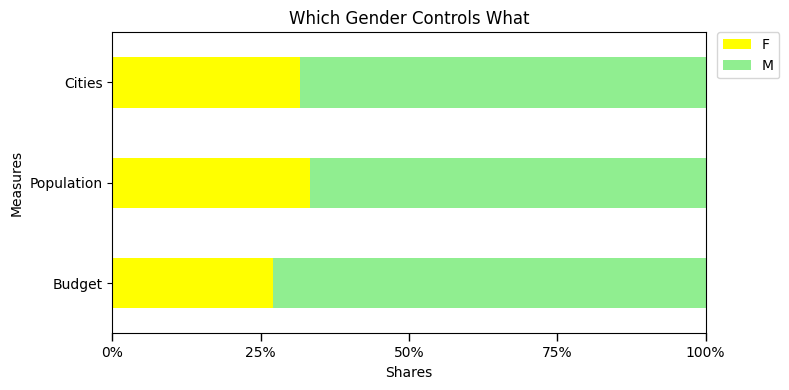

In [38]:
#part 6f: Project E: which gender controls the budget and the population?

total_budget_gender = df['Budget'].sum()
total_population_gender = df['Population'].sum()
budget_by_gender = df.groupby('Gender')['Budget'].sum()/total_budget_gender
pop_by_gender = df.groupby('Gender')['Population'].sum()/total_population_gender
cities_by_gender = df['Gender'].value_counts(normalize=True)

control_dict = {
    'Cities': cities_by_gender,
    'Population': pop_by_gender,
    'Budget': budget_by_gender
}

df_control = pd.DataFrame(control_dict)
print(df_control)

df_control = df_control.T
color_map = {
    'M': 'lightgreen',
    'F': 'yellow'
}

ax = df_control.plot.barh(stacked=True, color=color_map, title='Which Gender Controls What', figsize=(8,4))
ax.set_xlim(0,1.0)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0,decimals=0))
ax.tick_params(axis='x', which='major', bottom=True, length=6, width=1)
ax.set_xlabel('Shares')
ax.set_ylabel('Measures')
ax.invert_yaxis()
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()



Female mayors hold 31.6% of the cities and 33.2% of the population but only 27.0% of the budget (a 6.2-point drop), which may be partly explained by the fact that New York, with the largest budget, happens to have a male mayor.

<h1> Part 6 write-up </h1>

The Democratic caucus controls most of the budget and the population: it holds 86% of the cities, but 88.4% of the population and 90.8% of the budget, a 4.8-point increase once cities are weighted by people and dollars. An analysis of the medians tells us that a typical city in the Democratic caucus also spends more per resident, with a median \$75.59 higher than the typical Republican-led city.

<h1> Reflections </h1>

<ol>
<li><b>Which measure of center best describes a typical city’s population, and why?</b>
<p>The median best describes a typical city's population. With the mean population at 359,288 and the median standing at 202,010, the mean sits 77.9% above the median. 78.4% of the 250 cities fall below the mean while exactly 50% fall below the median. The long right tail of the distribution, which New York stretches with about 8.6 million residents, pulls the mean away from the typical city, whereas the median, which depends only on the middle city, lies unaffected by New York's large size.</p></li>
<li><b>What did the log transform do to the skewness of Population and to its empirical-rule percentages?</b>
<p>The log transform reduced the skewness of Population from 8.98 to 1.51 and pulled its empirical-rule percentages much closer to the expected values. Within one standard deviation, the raw Population held 95.6% of the cities against the 68% the rule expects, while log10_Population held 70.8%. Within two standard deviations, the log version sat only 1.0 percentage point above the expected 95% (96.0%), while the raw version sat 3.4 points above it (98.4%). The transform did not fully remove the asymmetry, however: a skewness of 1.51 remains above my cutoff of 1, so log10_Population keeps a long right-leaning tail.</p></li>
<li><b>Why did the z rule and the IQR rule remove different cities? Which do you trust more for this data?</b>
<p>  The z rule depends on the mean and standard deviation, which New York distorts (standard deviation 848.93, against 585.18 without it), so it removed only New York, masking Chicago, San Antonio and Columbus. The IQR rule uses rank-based quartiles, so it removed all four cities. I trust the IQR rule more for this data: it leaves less skewness (0.47 versus 0.86) and no dots beyond the box-plot whiskers.</p></li>
<li><b>When is min-max scaling a poor choice? What would you use instead?</b>
<p>Min-max scaling represents a poor choice when the data contain extreme outliers, because the minimum and maximum set the scale. New York (about 8.6 million residents) sets the top at exactly 1 and squeezes the other cities toward the left edge, so Boise (238,429 residents) gets 0.02 and Hesperia (102,605) gets 0.00, even though Boise has only 2.32 times as many residents. I favor using a robust version of the z-score, (x - median) ÷ IQR, which relies on the median and quartiles that New York barely moves and keeps every city in the analysis.</p></li>
<li><b>Is New York an error or a real extreme? Should it be removed, and what changes in your results if it is?</b>
<p>New York represents a real extreme, not an error. Its population of 8,584,629 matches the U.S. Census Bureau's July 2025 estimate. While I would not remove it altogether, I would compare the results with and without it, as this lab has explored. Without New York, the skewness of Budget per Capita falls from 6.26 to 0.86. The Republican bloc's share of the budget rises 3.3 points from 9.2% to 12.5%. Finally, the correlation between Population and Budget rises from 0.91 to 0.95. Keeping New York shows the full picture of the largest city, and removing it shows the more typical cities, so each view reveals information that the other does not.</p></li>
</ol>

<h1> Part 7: Power BI customizations</h1>

<p>In customizing script #4, "Who controls what" I made the following changes:</p>
<ol>
<li>Replaced Order with State_City as the visual's unique field</li>
<li>Fixed the indentation error for left += pct[b]</li>
<li>Replaced Bloc with Party in the fields and in the groupby lines</li>
<li>Named four parties and listed four colors, stacking D, NP, I and R</li>
<li>Wrote out the legend entries in full</li>
<li>Skipped labels on segments narrower than 4% to avoid crowding</li>
<li>Created a new title</li>
<li>Added a slicer that corresponds to City_Size</li>
</ol>
<p>I observed that visuals responded dynamically when testing with the Major and Small tiles. When I select Major, the Bloc chart shows the Republican segment at 16.7%, 8.4% and 5.5%, and the party chart shows only D and R, because no Independent or Nonpartisan mayor heads a Major city.
When looking at the charts in Small City_Size, the Republican segment displays 15.4%, 15.1% and 15.2%, and the Nonpartisans hold 50.5% of the cities. All values correspond to my notebook's Project B results.
</p>
<p>I sorted the slicer tiles themselves by first writing a Python script that created a column that assigns a numeric value to each City_Size and Budget_Size value. Then I set each tier column to sort by its order column (Major = 1 … Tiny = 5).</p>

<p>In customizing script #3, "Population vs budget" I made the following changes:</p>
<ol>
<li>Replaced Order with State_City as the visual's unique field, and added City_Size</li>
<li>Utilized Okabe-Ito colors (a color-blind-friendly palette) for the 5 City_Size tiers</li>
<li>Iterated over a Major to Tiny list, to preserve the tier order in the legend</li>
<li>Fixed indentation errors (replacing tabs with spaces)</li>
<li>Adapted the chart titles to reflect change in groupings ('by bloc' in chart 1 and 'by city size' in chart 2)</li>
<li>Created a trend line on the logarithms of both columns, with a slope of 1.14 in the legend</li>
</ol>

<p><i>Note on slope:</i> The trend line in this chart has a slope of 1.14. A slope above 1 means the budget grows faster than the population. I would estimate for a city with 10% more residents, about 11% more budget would emerge. In sum, the trend shows that larger cities spend proportionally more per resident.</p>
<p><i>Note on data type:</i>
I verified in Power Query that Population and Budget loaded as whole numbers. I also changed Budget_per_Capita to decimal to prevent cent truncation.
</p>
